<a href="https://colab.research.google.com/github/Sadie369/CodeAlpha/blob/main/Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PHASE 1: FETCHING BIOACTIVITY DATA FROM CHEMBL
Target Found: Beta-secretase 1 (ChEMBL ID: CHEMBL4822)
Successfully downloaded 9881 raw bioactivity rows.

PHASE 2: DATA CLEANING & pIC50 CALCULATION
Final full dataset size ready for training: 9588 compounds.

PHASE 3: HYBRID FEATURE EXTRACTION (FINGERPRINTS + DESCRIPTORS)
Feature Matrix Shape (X): (9588, 2058) (2048 FP bits + 10 Descriptors)
Target Vector Shape (y): (9588,)

PHASE 4: MODEL TRAINING & EVALUATION (XGBOOST)
Training XGBoost Regressor model...

--- Upgraded Model Performance Metrics ---
Test Root Mean Squared Error (RMSE): 0.698
Test R-squared ($R^2$) Score: 0.599

PHASE 5: VIRTUAL SCREENING OF CANDIDATE COMPOUNDS

--- Virtual Screening Leaderboard (XGBoost + Hybrid Features) ---
                       Compound  Predicted pIC50  Est. IC50 (µM)
            proanthocyanidin A1             7.75            0.02
            proanthocyanidin A2             7.75            0.02
                      Quercetin             6.27      

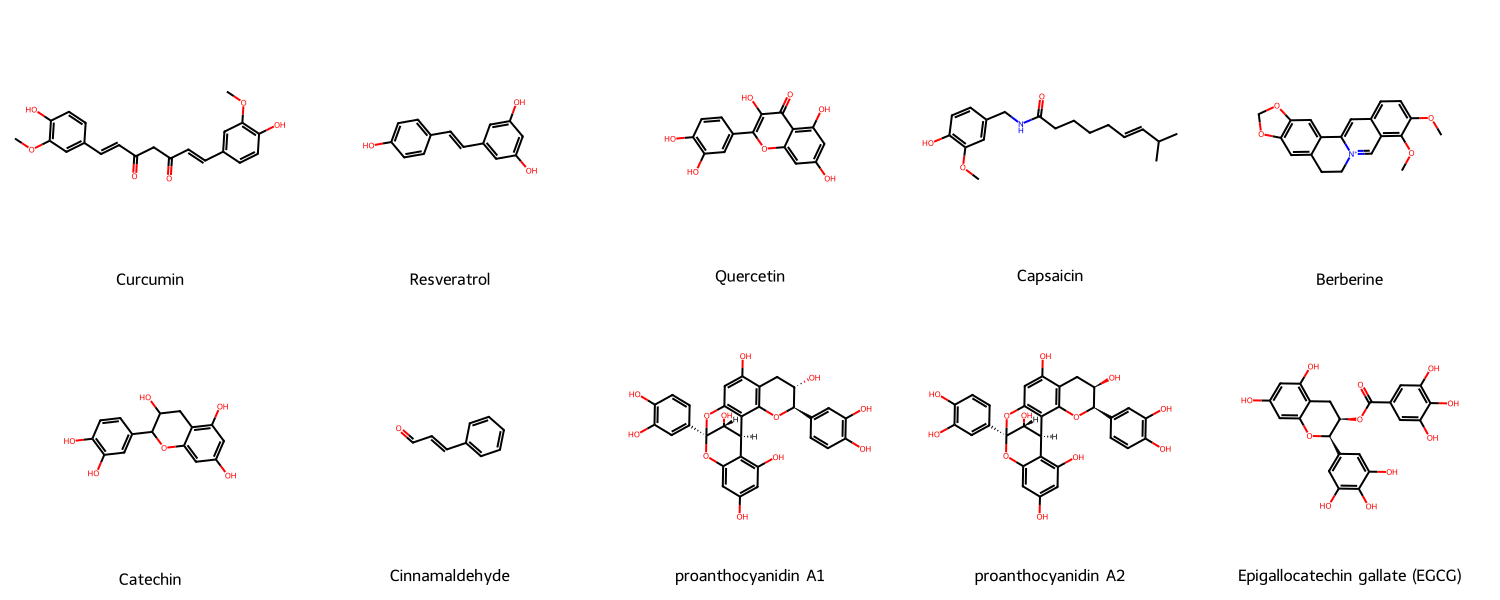

/tmp/ipykernel_557/4263198318.py:206: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_557/4263198318.py:225: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


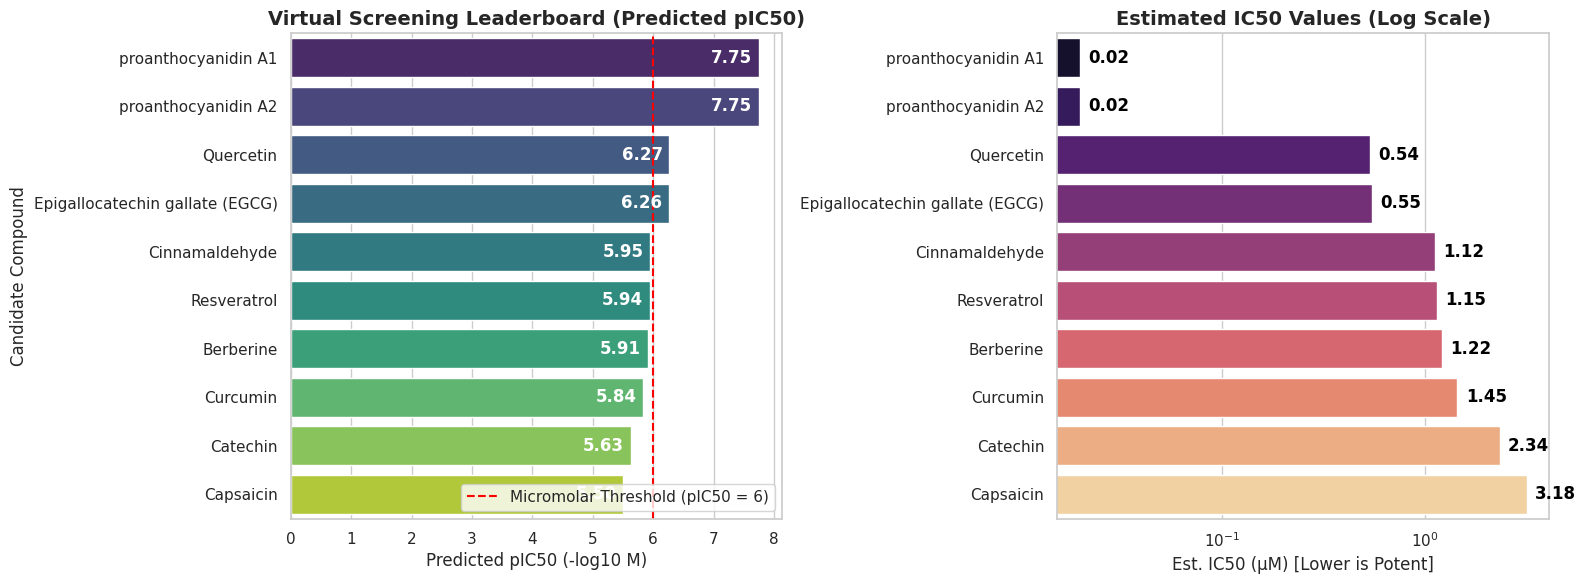

In [9]:
!pip install chembl-webresource-client rdkit xgboost scikit-learn numpy pandas

import numpy as np
import pandas as pd
from chembl_webresource_client.new_client import new_client
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs, Descriptors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

RDLogger.DisableLog('rdApp.warning')

print("=" * 50)
print("PHASE 1: FETCHING BIOACTIVITY DATA FROM CHEMBL")
print("=" * 50)

target_client = new_client.target
activity_client = new_client.activity

target_query = target_client.filter(pref_name__icontains="Beta-secretase 1")
target_chembl_id = target_query[0]["target_chembl_id"]
print(f"Target Found: Beta-secretase 1 (ChEMBL ID: {target_chembl_id})")

res = activity_client.filter(
    target_chembl_id=target_chembl_id, standard_type="IC50", units="nM"
).only(
    "molecule_chembl_id", "canonical_smiles", "standard_value", "standard_relation"
)

df = pd.DataFrame(list(res))
print(f"Successfully downloaded {len(df)} raw bioactivity rows.")

print("\n" + "=" * 50)
print("PHASE 2: DATA CLEANING & pIC50 CALCULATION")
print("=" * 50)

df = df.dropna(subset=["canonical_smiles", "standard_value"])
df["standard_value"] = df["standard_value"].astype(float)

df = df[(df["standard_relation"] == "=") & (df["standard_value"] > 0)]

df["pIC50"] = -np.log10(df["standard_value"] * 1e-9)
df = df.reset_index(drop=True)

print(f"Final full dataset size ready for training: {len(df)} compounds.")

print("\n" + "=" * 50)
print("PHASE 3: HYBRID FEATURE EXTRACTION (FINGERPRINTS + DESCRIPTORS)")
print("=" * 50)

def extract_features(smiles_str, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smiles_str)
    if mol is None:
        return None

    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    fp_arr = np.zeros((0,), dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, fp_arr)

    desc_arr = np.array([
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        Descriptors.NumHDonors(mol),
        Descriptors.NumHAcceptors(mol),
        Descriptors.NumRotatableBonds(mol),
        Descriptors.NumAromaticRings(mol),
        Descriptors.FractionCSP3(mol),
        Descriptors.RingCount(mol),
        Descriptors.HeavyAtomCount(mol)
    ], dtype=np.float32)

    return np.concatenate([fp_arr, desc_arr])

features_list = []
valid_indices = []

for idx, smi in enumerate(df["canonical_smiles"]):
    feat = extract_features(smi)
    if feat is not None:
        features_list.append(feat)
        valid_indices.append(idx)

X = np.array(features_list)
y = df.iloc[valid_indices]["pIC50"].values

print(f"Feature Matrix Shape (X): {X.shape} (2048 FP bits + 10 Descriptors)")
print(f"Target Vector Shape (y): {y.shape}")

print("\n" + "=" * 50)
print("PHASE 4: MODEL TRAINING & EVALUATION (XGBOOST)")
print("=" * 50)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training XGBoost Regressor model...")
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_scaled, y_train)

y_pred = xgb_model.predict(X_test_scaled)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n--- Upgraded Model Performance Metrics ---")
print(f"Test Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"Test R-squared ($R^2$) Score: {r2:.3f}")

print("\n" + "=" * 50)
print("PHASE 5: VIRTUAL SCREENING OF CANDIDATE COMPOUNDS")
print("=" * 50)

candidates = {
    "Curcumin": "COc1cc(/C=C/C(=O)CC(=O)/C=C/c2ccc(O)c(OC)c2)ccc1O",
    "Resveratrol": "Oc1ccc(cc1)C=Cc2cc(O)cc(O)c2",
    "Quercetin": "O=c1c(O)c(oc2cc(O)cc(O)c12)c3ccc(O)c(O)c3",
    "Capsaicin": "COc1cc(CNC(=O)CCCC/C=C/C(C)C)ccc1O",
    "Berberine": "COc1ccc2cc3[n+](cc2c1OC)CCc1cc2c(cc1-3)OCO2",
    "Catechin": "Oc1cc(O)c2c(c1)OC(c1ccc(O)c(O)c1)C(O)C2",
    "Cinnamaldehyde": "O=C/C=C/c1ccccc1",
    "proanthocyanidin A1": "Oc1cc(O)c2c(c1)O[C@@]1(c3ccc(O)c(O)c3)Oc3cc(O)c4c(c3[C@@H]2[C@H]1O)O[C@H](c1ccc(O)c(O)c1)[C@@H](O)C4",
    "proanthocyanidin A2": "Oc1cc(O)c2c(c1)O[C@@]1(c3ccc(O)c(O)c3)Oc3cc(O)c4c(c3[C@@H]2[C@H]1O)O[C@H](c1ccc(O)c(O)c1)[C@H](O)C4",
    "Epigallocatechin gallate (EGCG)": (
        "O=C(O[C@@H]1Cc2c(O)cc(O)cc2O[C@@H]1c1cc(O)c(O)c(O)c1)c1cc(O)c(O)c(O)c1"
    ),
}

screening_results = []

for name, smi in candidates.items():
    feat = extract_features(smi)
    if feat is not None:
        feat_scaled = scaler.transform(feat.reshape(1, -1))
        pred_pic50 = xgb_model.predict(feat_scaled)[0]
        est_ic50_um = (10 ** (-pred_pic50)) * 1e6

        screening_results.append({
            "Compound": name,
            "Predicted pIC50": round(float(pred_pic50), 2),
            "Est. IC50 (µM)": round(float(est_ic50_um), 2),
        })

screening_df = pd.DataFrame(screening_results).sort_values(
    by="Predicted pIC50", ascending=False
)

print("\n--- Virtual Screening Leaderboard (XGBoost + Hybrid Features) ---")
print(screening_df.to_string(index=False))
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit.Chem import Draw

print("Generating molecular structure grid...")

mols = []
labels = []

for name, smi in candidates.items():
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        mols.append(mol)
        labels.append(name)

img = Draw.MolsToGridImage(
    mols,
    molsPerRow=5,
    subImgSize=(300, 300),
    legends=labels,
    useSVG=False
)

try:
    img.save("screening_candidates_structures.png")
except AttributeError:
    with open("screening_candidates_structures.png", "wb") as f:
        f.write(img.data)

display(img)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=screening_df,
    x="Predicted pIC50",
    y="Compound",
    palette="viridis",
    ax=axes[0]
)
axes[0].set_title("Virtual Screening Leaderboard (Predicted pIC50)", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Predicted pIC50 (-log10 M)", fontsize=12)
axes[0].set_ylabel("Candidate Compound", fontsize=12)
axes[0].axvline(x=6.0, color="red", linestyle="--", label="Micromolar Threshold (pIC50 = 6)")
axes[0].legend(loc="lower right")

for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(f"{width:.2f}",
                     (width - 0.45, p.get_y() + p.get_height() / 2.),
                     ha='center', va='center', color='white', fontweight='bold')

sns.barplot(
    data=screening_df,
    x="Est. IC50 (µM)",
    y="Compound",
    palette="magma",
    ax=axes[1]
)
axes[1].set_xscale("log")
axes[1].set_title("Estimated IC50 Values (Log Scale)", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Est. IC50 (µM) [Lower is Potent]", fontsize=12)
axes[1].set_ylabel("")

for p in axes[1].patches:
    width = p.get_width()
    axes[1].annotate(f"{width:.2f}",
                     (width * 1.1, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', color='black', fontweight='bold')

plt.tight_layout()
plt.show()